In [59]:
#Importa a biblioteca pandas
import pandas as pd
#importa a biblioteca para plotar gráfico
import matplotlib.pyplot as plt
import seaborn as sns

#Cria dicionario chamado dados
dados = {
    "produtos":["Motor A","Motor B","Motor A", "Motor C", "Motor B"],
    "producao":[100,120,110,90,130],
    "defeitos":[5,12,6,3,15],
    "temperatura":[70,82,73,68,85]
}


In [60]:
dados #Exibe o dicionário criado

{'produtos': ['Motor A', 'Motor B', 'Motor A', 'Motor C', 'Motor B'],
 'producao': [100, 120, 110, 90, 130],
 'defeitos': [5, 12, 6, 3, 15],
 'temperatura': [70, 82, 73, 68, 85]}

In [61]:
# Transformando o dicionario dados em um dataframe
df = pd.DataFrame(dados)

In [62]:
# Exibir as primeiras linhas do Dataframe
df.head(5)

,produtos,producao,defeitos,temperatura
0,Motor A,100,5,70
1,Motor B,120,12,82
2,Motor A,110,6,73
3,Motor C,90,3,68
4,Motor B,130,15,85


In [63]:
# Verificando os tipos de dados do Dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   produtos     5 non-null      object
 1   producao     5 non-null      int64 
 2   defeitos     5 non-null      int64 
 3   temperatura  5 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 292.0+ bytes


In [64]:
# Analisando os dados com estatística mínima
df.describe()

,producao,defeitos,temperatura
count,5.000000,5.000000,5.000000
mean,110.000000,8.200000,75.600000
std,15.811388,5.069517,7.503333
min,90.000000,3.000000,68.000000
25%,100.000000,5.000000,70.000000
50%,110.000000,6.000000,73.000000
75%,120.000000,12.000000,82.000000
max,130.000000,15.000000,85.000000


In [65]:
# Selecionando uma coluna
df['temperatura']

,temperatura
0,70
1,82
2,73
3,68
4,85


In [66]:
X = df['temperatura']
type(X)


pandas.core.series.Series

In [67]:
#Verificando o tipo de variavel
n=5.1
type(n)

float

In [68]:
# Selecionar mais de uma coluna
df[["produtos","temperatura"]]

,produtos,temperatura
0,Motor A,70
1,Motor B,82
2,Motor A,73
3,Motor C,68
4,Motor B,85


In [69]:
#Filtro de dados simples com uma condição só
df[df['temperatura']>75]


,produtos,producao,defeitos,temperatura
1,Motor B,120,12,82
4,Motor B,130,15,85


In [70]:
# Filtro de dados com mais de uma condição
#print(df[df['temperatura'] >10])
df[(df['temperatura']>75) & (df['defeitos'] >10)]

,produtos,producao,defeitos,temperatura
1,Motor B,120,12,82
4,Motor B,130,15,85


In [71]:
# Calculando a média da coluna de temperatura
df['temperatura'].mean()

np.float64(75.6)

In [72]:
#Calculando a média da produção
df['producao'].mean()

np.float64(110.0)

In [73]:
#Identificando a temperatura máxima
df['temperatura'].max()

85

In [74]:
# Idenficando a temperatura mínima
df['temperatura'].min()

68

In [75]:
#Ordenando por maior temperatura para a menor temperatura
df.sort_values(by='temperatura', ascending=False)

,produtos,producao,defeitos,temperatura
4,Motor B,130,15,85
1,Motor B,120,12,82
2,Motor A,110,6,73
0,Motor A,100,5,70
3,Motor C,90,3,68


In [76]:
#Ordenando por menor temperatura para a maior temperatura
df.sort_values(by='temperatura', ascending=True)

,produtos,producao,defeitos,temperatura
3,Motor C,90,3,68
0,Motor A,100,5,70
2,Motor A,110,6,73
1,Motor B,120,12,82
4,Motor B,130,15,85


In [77]:
# Identificando a linha que tem o valor mínimo
print(df.loc[df['temperatura'].idxmin()])

produtos       Motor C
producao            90
defeitos             3
temperatura         68
Name: 3, dtype: object


In [78]:
# Agrupar a produção média por produto
df.groupby('produtos')['producao'].mean()

,producao
produtos,
Motor A,105.0
Motor B,125.0
Motor C,90.0


In [79]:
# Agrupar defeitos médios por produto
df.groupby('produtos')['defeitos'].mean()

,defeitos
produtos,
Motor A,5.5
Motor B,13.5
Motor C,3.0


In [80]:
# Calculando uma estatística do dataframe

df.groupby('produtos').agg({
    'producao':'mean',
    'defeitos':'sum',
    'temperatura':'mean'
})

,producao,defeitos,temperatura
produtos,,,
Motor A,105.0,11,71.5
Motor B,125.0,27,83.5
Motor C,90.0,3,68.0


In [81]:
# Calculando taxa de defeitos
df['taxa_defeitos'] = (df['defeitos'] / df['producao']) *100

In [82]:
df['taxa_defeitos']

,taxa_defeitos
0,5.000000
1,10.000000
2,5.454545
3,3.333333
4,11.538462


In [83]:
# Correlação
df[['producao','defeitos','temperatura']].corr()

,producao,defeitos,temperatura
producao,1.000000,0.966863,0.969334
defeitos,0.966863,1.000000,0.995051
temperatura,0.969334,0.995051,1.000000


In [84]:
# Cria uma variavel para poder armazenar a correlaçao
corr= df[['producao','defeitos','temperatura']].corr()

In [85]:
corr

,producao,defeitos,temperatura
producao,1.000000,0.966863,0.969334
defeitos,0.966863,1.000000,0.995051
temperatura,0.969334,0.995051,1.000000


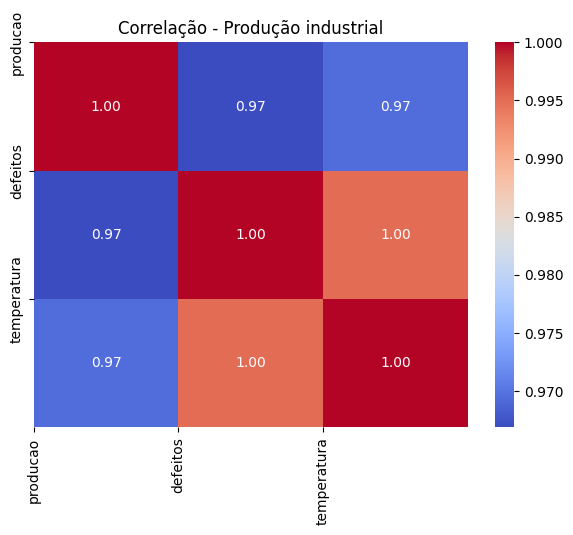

In [88]:
# Criar o grafico de correlação
plt.figure(figsize=(7,5))

sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f')

plt.title("Correlação - Produção industrial")
plt.xticks(range(len(corr)), corr.columns, rotation='vertical')
plt.yticks(range(len(corr)), corr.columns)
plt.show()